# 11 Alignment arrays: the event history at Tule Pond before InSAR

```
Author: Danielle Lindsay
Environment: opera_disp_feb13. Run time: seconds.
```

**What this notebook does.** The USGS Bay Area alignment arrays (archive v3.0; McFarland et al. 2017) record
surface slip at Tule Pond over 45 years. Six arrays span the section. HRKT (inside the section) and HAPP (1.6 km
north of it) were surveyed about every two months from 1979 to 2007 (HRKT to mid-2007) and annually after that.
HCAM and HPMD (about 3 km south) were surveyed about every two months from 1990-92 to 2007, and the other arrays
annually.

1. **Array positions and the InSAR at each array** (sections 2 to 5). The positions (latitude, longitude) are read
   from the archive summary and checked against the mapped trace. The InSAR fault-parallel series within 0.5 km
   along strike of each array (`stack_km`) are averaged and the average is tied to the array by a constant offset.
   The array step across each InSAR onset window is measured. The supplement figure shows the map and the six
   arrays since 2015.
2. **The HRKT event history, bimonthly era only** (section 6). An event is a survey interval whose step exceeds the
   inter-event rate by a fixed 6 mm. The flagged intervals are fitted with the joint model of notebook 04, and
   detections with a fitted step under 2 sigma are dropped. The 6 mm threshold was chosen by eye against visually
   distinct steps; the threshold sweep (step 4) shows the effect of this choice. Notebook 12 (event table,
   seasonality) and notebook 13 (repeat intervals and forecast) read the catalogue. The repeat intervals are
   computed only in notebook 13.
3. **Along strike** (section 7). The same detector is run on HAPP, HCAM and HPMD, and their excess step inside every
   HRKT event window is measured.
4. **Threshold sweep** (section 9, supplement). The detector is run with thresholds of 3 sigma, 6 mm and 5 mm.

**Inputs**: 03 `fp_ts.csv`; 04 `creep_events.csv` (the InSAR onset windows, where `onset_lo` is the last acquisition
before the step, which is also the step epoch of 04, and `onset_hi` the first acquisition after it); 04
`section_lengths.csv` and 06 `fig2_inputs.npz` (for the map, the mean-event fault-parallel field and the SSE
extent); the archive summary; the array files of HAPP, HGIL, HRKT, HHAN, HUNI, HPIN, HCAM and HPMD; the mapped trace.

**Outputs** (`outputs/11_alignment_arrays/`): `hrkt_aa_events.csv` (for each array event the survey window
`onset_lo` to `onset_hi`, its step, and `onset_mid`, the window midpoint, used only for labels, plot positions and
sorting); `aa_insar_stacks.csv` (read by 12 and 14); `aa_insar_steps.csv`; `aa_alongstrike_neighbours.csv`;
`hrkt_threshold_sweep.csv`; the map panel `qc_arrays_map_panel.png` and its colour table `event_RdBu_r.cpt`;
the stats sidecar `11_aa_stats.txt`; registry rows `11_*` (including `11_hgil_*` and `11_hrkt_*`, the step medians of
section 4).

**Figures**: the six-array supplement figure (`figS_tulepond_arrays_insar_*`); the threshold sweep
(`figS_hrkt_threshold_sweep_3sig-6mm-5mm`, supplement); QC figures of the HRKT and HAPP records
(`qc_aa_history_*`). The paper's Fig 3 is drawn by 14_paper_figures.

**What to check.** Every array lies within 150 m of the trace (asserted, section 2). The end of the HRKT bimonthly
era (`11_hrkt_dense_era_end_yr`) is printed in section 6. The longest quiet interval spans Loma Prieta (asserted,
section 6). The excess of the neighbouring arrays inside the HRKT windows, in units of sigma, is printed in
section 7. Every value is registered in section 10.

## 1. Imports and settings

The detector settings, the arrays, the colours and the input files. The registry records the input files.

In [1]:
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import common_paths, creepmeters, params, paths_out, repo_dir, aa_dense_window_days, loma_prieta_yr

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
from scipy.spatial import cKDTree                 # nearest trace vertex (map: which side of the fault)
import pygmt                                     # the map panel
import xarray as xr                              # gridded data for pygmt
import matplotlib.pyplot as plt

In [2]:
notebook = "11_alignment_arrays"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


stack_km = 0.5                 # half-width along strike of the InSAR stack around each array (km)
site = "HRKT"                  # the array with the dense record
thr_mm = 6.0                   # detection threshold: fixed excess per survey interval, chosen by eye (see the sweep)
min_step_sigma = 2.0           # a detection is kept only if its fitted step is at least this many sigma
n_pass = 2                     # detector passes (pass 2 uses the fitted inter-event rate)
dense_window_days = aa_dense_window_days   # the bimonthly era: survey intervals up to this (d); the detector runs only there (TulePond_filepaths, shared with 12 and 13)
n_background = 4               # columns of the joint model before the steps: constant, rate, annual sin, annual cos
neighbour_codes = ["HAPP", "HCAM", "HPMD"]   # the other arrays surveyed every ~2 months: north (HAPP) and south (HCAM, HPMD) of the section
zoom_t0 = 2015.0               # start of the zoomed panels
loma_prieta = loma_prieta_yr   # 17 Oct 1989 (TulePond_filepaths, shared with 12 and 13)
# the six arrays across the section, north to south; their positions (lat and lon) are read from the archive
# summary in section 2 and checked against the mapped trace
array_codes = ["HAPP", "HGIL", "HRKT", "HHAN", "HUNI", "HPIN"]
max_trace_dist_m = 150.0       # every array must sit within this distance of the mapped trace
# the map panel: 06's mean-event fault-parallel field on the shared rotated fault map of Fig 1A
event_field_file = os.path.join(paths_out["06_event_field_geometry"], "fig2_inputs.npz")   # the field Fig 2 maps
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")        # the SSE extent bracket
strike_map = 144.0             # page rotation of the map (mean strike, notebook 02; as Fig 1A)
map_h_cm = 9.2                 # map height (cm, as Fig 1A); the width follows at true scale
map_u_km = (42.0, 70.0)        # along-strike extent of the map (km from Point Pinole): just north of CHP1 (Hayward) to the south end of Fig 1A
map_half_km = 4.5              # across-fault half-width of the map (km)
event_lim = 5.0                # map colour range, +/- mm of event slip
array_label_u_km = [46.5, 49.0, 51.5, 54.0, 56.5, 59.0]   # along-strike km of the six array codes (north to south), north of CFW1 (62.2) and the scale bar

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
# Okabe-Ito colours (no green): array blue, InSAR vermillion, InSAR onset lines orange in the QC figures
aa_color = "#0072B2"
insar_color = "#D55E00"
det_color = "#E69F00"

REG = utils.Registry(notebook, common_paths, repo_dir)
array_files = []
for code in array_codes + ["HCAM", "HPMD"]:
    array_files.append(os.path.join(common_paths["aa_dir"], f"{code}.csv"))
REG.inputs(fp_ts_file, events_file, common_paths["aa_summary"], event_field_file, lengths_file, common_paths["fault_profiles"], *array_files)

Registry for 11_alignment_arrays: run 003f285f, git e7a9e3b


## 2. Load the InSAR fault-parallel series, the InSAR catalogue and the arrays

The InSAR onsets come from 04 as windows. `onset_lo` is the last acquisition before the step and is the step epoch
of 04 (its step is $H(t - t_\mathrm{lo})$, defined in section 3); `onset_hi` is the first acquisition after it.

The array positions come from the archive summary. The along-strike distance of an array (km from Point Pinole) is
computed from its latitude, as for the InSAR crossings. The distance of an array to the mapped trace is measured on
a flat earth,

$$d = \min_j \sqrt{\left[(\lambda_j - \lambda)\, k_\lambda\right]^2 + \left[(\varphi_j - \varphi)\, k_\varphi\right]^2},$$

where $(\varphi, \lambda)$ are the latitude and longitude of the array (degrees), $(\varphi_j, \lambda_j)$ those of
trace vertex $j$ (vertices every 100 m), $k_\varphi = 111.19$ km per degree and
$k_\lambda = 111.19 \cos\bar\varphi$ km per degree, with $\bar\varphi$ the mean latitude of the trace. Because $d$ is
measured to the nearest vertex rather than to the line, it overestimates the distance by up to about 50 m.

In [3]:
# the fault-parallel time series from 03: lat x decimal year, mm
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])    # latitude -> km from Point Pinole along the trace
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_dates = fp_ts.columns.values.astype(float)

# the InSAR event catalogue from 04, Tule Pond only
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"]
insar_events = insar_events[["onset_lo", "onset_hi"]]
insar_events = insar_events.sort_values("onset_lo").reset_index(drop=True)
assert (insar_events.onset_lo < insar_events.onset_hi).all(), "an InSAR onset window that does not run forward in time"
print("InSAR onset windows:")
for event in insar_events.itertuples():
    print(f"  {event.onset_lo:.3f} to {event.onset_hi:.3f}")

# the six arrays: year, cum_mm, std_mm each
arrays = {}
for code in array_codes:
    arrays[code] = utils.load_aa(common_paths["aa_dir"], code)
for code, array in arrays.items():
    print(f"  {code}: {len(array)} surveys {array.year.min():.2f} to {array.year.max():.2f}, "
          f"median spacing {np.median(np.diff(array.year)) * 365.25:.0f} d, "
          f"{array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr over the record")

# the array positions: lat and lon from the archive summary. The along-strike km is taken from the array's own
# latitude (as the InSAR crossings are); the distance to the mapped trace is to its nearest 100 m vertex, so it
# is an upper bound (by up to ~50 m) on the distance to the line itself.
summary = utils.load_aa_summary(common_paths["aa_summary"]).set_index("site_code")
trace = pd.read_csv(common_paths["fault_profiles"])          # the mapped trace: ft_lon, ft_lat every 100 m
km_per_deg_lat = 111.19
km_per_deg_lon = 111.19 * np.cos(np.radians(trace.ft_lat.mean()))
position_rows = []
for code in array_codes:
    lat = float(summary.loc[code, "lat_deg"])
    lon = float(summary.loc[code, "long_deg"])
    dist_km = np.hypot((trace.ft_lon.values - lon) * km_per_deg_lon, (trace.ft_lat.values - lat) * km_per_deg_lat)
    position_rows.append(dict(code=code, lat=lat, lon=lon, km=float(to_km([lat])[0]), dist_to_trace_m=1e3 * float(dist_km.min())))
array_pos = pd.DataFrame(position_rows).set_index("code")
print(array_pos.round({"lat": 4, "lon": 4, "km": 1, "dist_to_trace_m": 0}).to_string())
assert (array_pos.dist_to_trace_m <= max_trace_dist_m).all(), f"an array lies more than {max_trace_dist_m:g} m from the mapped trace"

InSAR onset windows:
  2017.101 to 2017.133
  2019.187 to 2019.203
  2021.109 to 2021.125
  2023.080 to 2023.113
  2024.986 to 2025.018
  AA HAPP: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1995.007 vs 1/28/1995, 1996.820 vs 10/22/1996, 2024.680 vs 10/5/2024; 0 without a readable date
  AA HPIN: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2023.910 vs 11/26/2023; 0 without a readable date
  HAPP: 174 surveys 1979.73 to 2024.68, median spacing 64 d, 6.00 mm/yr over the record
  HGIL: 45 surveys 1983.76 to 2024.93, median spacing 365 d, 5.99 mm/yr over the record
  HRKT: 177 surveys 1979.72 to 2024.72, median spacing 63 d, 5.73 mm/yr over the record
  HHAN: 30 surveys 1982.04 to 2024.72, median spacing 367 d, 6.22 mm/yr over the record
  HUNI: 34 surveys 1993.02 to 2024.82, median spacing 364 d, 6.65 mm/yr over the record
  HPIN: 36 surveys 1989.22 to 

## 3. The InSAR stack at each array

The stack at an array is the mean of the fault-parallel series of the crossings within `stack_km` along strike of
the array, leaving out crossings with data on fewer than half the dates:

$$\bar u(t_j) = \frac{1}{N_c} \sum_{c=1}^{N_c} u_c(t_j),$$

where $u_c(t_j)$ is the fault-parallel slip of crossing $c$ at acquisition $t_j$ (mm) and $N_c$ the number of
crossings with data at $t_j$. The stack is tied to the array by a constant offset (a vertical shift only; nothing is
fitted),

$$\Delta = \frac{1}{N_s} \sum_{k=1}^{N_s} \left[ U(\tau_k) - \bar u(\tau_k) \right],$$

where $U(\tau_k)$ is the cumulative array slip at survey $\tau_k$ (mm), the sum runs over the $N_s$ surveys inside
the InSAR record (asserted: every array has at least one), and $\bar u(\tau_k)$ is the stack interpolated linearly to
the survey time. The tied stack is $\bar u + \Delta$.

The five event steps are then measured on the HRKT stack with the joint model of 04,

$$u(t) = c + v\,(t - \bar t) + a \sin 2\pi t + b \cos 2\pi t + \sum_{k=1}^{K} s_k\, H(t - \tau_k),$$

where $u(t)$ is the slip at time $t$ (mm; $t$ in decimal years), $\bar t$ the mean of the epochs, $c$ a constant
(mm), $v$ the inter-event rate (mm/yr), $a$ and $b$ the annual sine and cosine amplitudes (mm), $s_k$ the step of
event $k$ (mm), $\tau_k$ its step epoch (here `onset_lo` of 04), $K$ the number of events, and $H(x) = 1$ for
$x > 0$ and 0 otherwise. The model is solved by least squares. The steps of 04 are measured on its peak-slip band
stack, not at HRKT, so these steps compare the InSAR-era events with the array steps at the same place.

In [4]:
def design_matrix(dates, step_epochs):
    """Design matrix of the joint model of 04 (section 3).

    Parameters
    ----------
    dates : numpy.ndarray
        Epochs (decimal years).
    step_epochs : sequence of float
        Step epoch of each event (decimal years); the step is H(t > step epoch).

    Returns
    -------
    numpy.ndarray
        Columns: constant, rate (time minus the mean epoch), annual sine, annual cosine, then one step per event.
    """
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    for step_epoch in step_epochs:
        columns.append((dates > step_epoch).astype(float))
    return np.column_stack(columns)


def insar_stack(code, array):
    """InSAR stack at one array, tied to the array by a constant offset (section 3).

    Parameters
    ----------
    code : str
        Array code.
    array : pandas.DataFrame
        The array record (year, cum_mm, std_mm).

    Returns
    -------
    dates : numpy.ndarray
        Acquisition epochs with data (decimal years).
    slip : numpy.ndarray
        Tied stack (mm).
    n_crossings : int
        Number of crossings in the stack.
    """
    crossing_km = to_km(fp_ts.index.values.astype(float))      # fp_ts is indexed by latitude: along-strike km of each crossing
    array_km = float(array_pos.km[code])
    nearby = fp_ts[np.abs(crossing_km - array_km) <= stack_km]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)          # all-NaN dates give NaN, dropped just below
        slip = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(slip)
    dates = fp_dates[ok]
    slip = slip[ok]
    # tie: mean offset at the surveys inside the InSAR record
    in_window = array[(array.year >= dates.min()) & (array.year <= dates.max())]
    assert len(in_window) > 0, f"{code}: no survey inside the InSAR window to tie the stack on"
    offset = float(np.mean(in_window.cum_mm.values - np.interp(in_window.year.values, dates, slip)))
    return dates, slip + offset, len(nearby)


stacks = {}                                       # code -> (dates, slip_mm, n_crossings)
for code, array in arrays.items():
    stacks[code] = insar_stack(code, array)

# saved for notebooks 12 and 14; 14_paper_figures draws the paper's Fig 3
stack_rows = []
for code, (insar_dates, insar_slip, n_crossings) in stacks.items():
    for date, slip in zip(insar_dates, insar_slip):
        stack_rows.append(dict(code=code, date=date, slip_mm=slip, n_crossings=n_crossings))
pd.DataFrame(stack_rows).to_csv(os.path.join(out_dir, "aa_insar_stacks.csv"), index=False)

# the five event steps on the HRKT stack (section 3), with the steps at the step epochs onset_lo of 04
hrkt_dates, hrkt_slip, hrkt_n = stacks["HRKT"]
G_hrkt = design_matrix(hrkt_dates, insar_events.onset_lo)
hrkt_insar_steps = np.linalg.lstsq(G_hrkt, hrkt_slip, rcond=None)[0][n_background:]
assert len(hrkt_insar_steps) == len(insar_events) and np.all(np.isfinite(hrkt_insar_steps))
print(f"HRKT InSAR stack ({hrkt_n} crossings): event steps {np.round(hrkt_insar_steps, 1)} mm, mean {hrkt_insar_steps.mean():.1f}, "
      f"median {np.median(hrkt_insar_steps):.1f}, range {hrkt_insar_steps.min():.1f}-{hrkt_insar_steps.max():.1f} (registered beside the mean)")

HRKT InSAR stack (10 crossings): event steps [6.8 6.8 6.1 5.3 6.5] mm, mean 6.3, median 6.5, range 5.3-6.8 (registered beside the mean)


## 4. The arrays against the InSAR at each site

For each InSAR onset window, the array step is

$$\Delta U = U(\tau_\mathrm{after}) - U(\tau_\mathrm{before}),$$

where $\tau_\mathrm{before}$ is the last survey on or before `onset_lo`, $\tau_\mathrm{after}$ the first survey on or
after `onset_hi`, and $U$ the cumulative array slip (mm). No survey may fall inside a window (asserted). Since 2015
(`zoom_t0`), each survey interval is classed as an event interval if it contains a whole InSAR onset window and as a
quiet interval otherwise, and the median step of each class is computed. The HGIL and HRKT medians are registered.

In [5]:
stats_lines = ["11 ALIGNMENT ARRAYS",
               f"InSAR stack: crossings within +/-{stack_km:g} km of each array; tie: mean offset at surveys inside the InSAR window"]
onset_text = []
for event in insar_events.itertuples():
    onset_text.append(f"{event.onset_lo:.3f}-{event.onset_hi:.3f}")
stats_lines += ["InSAR onset windows: " + ", ".join(onset_text), ""]
step_rows = []
for code, array in arrays.items():
    insar_dates, insar_slip, n_crossings = stacks[code]
    in_window = array[(array.year >= insar_dates.min()) & (array.year <= insar_dates.max())]
    stats_lines.append(f"{code} (km {array_pos.km[code]:.1f}, {array_pos.dist_to_trace_m[code]:.0f} m from the trace), stack {n_crossings} crossings; array {array.year.min():.2f}-{array.year.max():.2f}, "
                       f"{len(array)} surveys, {array.cum_mm.iloc[-1] / (array.year.max() - array.year.min()):.2f} mm/yr; "
                       f"InSAR {(insar_slip[-1] - insar_slip[0]) / (insar_dates[-1] - insar_dates[0]):.2f} mm/yr, {len(in_window)} surveys in window")
    # the array step across each InSAR onset window: first survey after the window minus last survey before it
    for event in insar_events.itertuples():
        inside = array[(array.year > event.onset_lo) & (array.year < event.onset_hi)]
        assert len(inside) == 0, f"{code}: a survey falls inside the InSAR onset window {event.onset_lo:.3f}-{event.onset_hi:.3f}"
        before = array[array.year <= event.onset_lo]
        after = array[array.year >= event.onset_hi]
        if len(before) and len(after):
            survey_before = before.iloc[-1]
            survey_after = after.iloc[0]
            step_mm = survey_after.cum_mm - survey_before.cum_mm
            stats_lines.append(f"    {event.onset_lo:.3f}-{event.onset_hi:.3f}: array step {step_mm:+5.1f} mm over "
                               f"{survey_before.year:.2f}-{survey_after.year:.2f} ({(survey_after.year - survey_before.year) * 365.25:.0f} d)")
            step_rows.append(dict(code=code, onset_lo=event.onset_lo, onset_hi=event.onset_hi, step_mm=step_mm,
                                  from_yr=survey_before.year, to_yr=survey_after.year))
        else:
            stats_lines.append(f"    {event.onset_lo:.3f}-{event.onset_hi:.3f}: not bracketed by surveys")
    # since zoom_t0: survey intervals that contain an InSAR onset window against those that do not
    recent = array[array.year >= zoom_t0].reset_index(drop=True)
    event_steps = []
    quiet_steps = []
    for i in range(1, len(recent)):
        step_mm = float(recent.cum_mm.iloc[i] - recent.cum_mm.iloc[i - 1])
        has_event = False
        for event in insar_events.itertuples():
            if recent.year.iloc[i - 1] <= event.onset_lo and event.onset_hi <= recent.year.iloc[i]:
                has_event = True
        if has_event:
            event_steps.append(step_mm)
        else:
            quiet_steps.append(step_mm)
    if event_steps and quiet_steps:
        stats_lines.append(f"    intervals since {zoom_t0:.0f}: with an event {np.median(event_steps):+5.1f} mm (median, n = {len(event_steps)}) "
                           f"vs quiet {np.median(quiet_steps):+5.1f} mm (n = {len(quiet_steps)})")
        step_rows.append(dict(code=code, step_mm=np.median(event_steps), from_yr=np.nan, to_yr=np.nan, kind="event_median", n=len(event_steps)))
        step_rows.append(dict(code=code, step_mm=np.median(quiet_steps), from_yr=np.nan, to_yr=np.nan, kind="quiet_median", n=len(quiet_steps)))
    stats_lines.append("")
aa_steps = pd.DataFrame(step_rows)
aa_steps.to_csv(os.path.join(out_dir, "aa_insar_steps.csv"), index=False)
print("\n".join(stats_lines))

11 ALIGNMENT ARRAYS
InSAR stack: crossings within +/-0.5 km of each array; tie: mean offset at surveys inside the InSAR window
InSAR onset windows: 2017.101-2017.133, 2019.187-2019.203, 2021.109-2021.125, 2023.080-2023.113, 2024.986-2025.018

HAPP (km 54.6, 45 m from the trace), stack 9 crossings; array 1979.73-2024.68, 174 surveys, 6.00 mm/yr; InSAR 5.39 mm/yr, 8 surveys in window
    2017.101-2017.133: array step  +7.4 mm over 2016.76-2017.79 (376 d)
    2019.187-2019.203: array step  +7.4 mm over 2018.80-2019.82 (370 d)
    2021.109-2021.125: array step +11.3 mm over 2019.82-2021.87 (749 d)
    2023.080-2023.113: array step  +7.5 mm over 2022.79-2023.86 (391 d)
    2024.986-2025.018: not bracketed by surveys
    intervals since 2015: with an event  +7.4 mm (median, n = 4) vs quiet  +6.6 mm (n = 4)

HGIL (km 58.0, 18 m from the trace), stack 11 crossings; array 1983.76-2024.93, 45 surveys, 5.99 mm/yr; InSAR 6.20 mm/yr, 8 surveys in window
    2017.101-2017.133: array step +18.1 mm ov

## 5. Supplement figure: the six arrays and the InSAR

Panel A is the rotated fault map of Fig 1A, drawn by the same function (`utils.fault_map_panel`: trace, cities,
creepmeters, SSE extent, distance from Point Pinole), over the mean-event fault-parallel field of 06, the field
mapped in Fig 2. The six arrays are black squares, each tied to its code by a thin leader. Panels B to G show each
array since 2015 (blue, with survey error bars), the InSAR stack tied to it (vermillion) and the five InSAR step
epochs `onset_lo` (grey dashed; the 6 to 12 d window is narrower than the line at this scale). The map is drawn
with pygmt and placed in the matplotlib figure as a 600 dpi PNG.

For display, the field is referenced to the mid-point of the median slip on the two sides of the trace,
$u_\mathrm{ref} = \tfrac{1}{2}(\tilde u_W + \tilde u_E)$, where $\tilde u_W$ and $\tilde u_E$ are the medians of the
field west and east of the trace (mm). A map node lies east of the trace when

$$d_x\,(y - y_0) - d_y\,(x - x_0) > 0,$$

where $(x, y)$ is the node, $(x_0, y_0)$ the nearest trace vertex, and $(d_x, d_y)$ the trace direction from the
vertex before to the vertex after the nearest one, turned to point south; all are in km on the flat-earth scale of
section 2.

mean event display reference: west -0.09, east -0.11 mm; mid-point removed
map panel 3.08 x 9.20 cm at true scale


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_tulepond_arrays_insar_ap30-150m_coh0.7_mp5_sw200m_stack0.5km.png


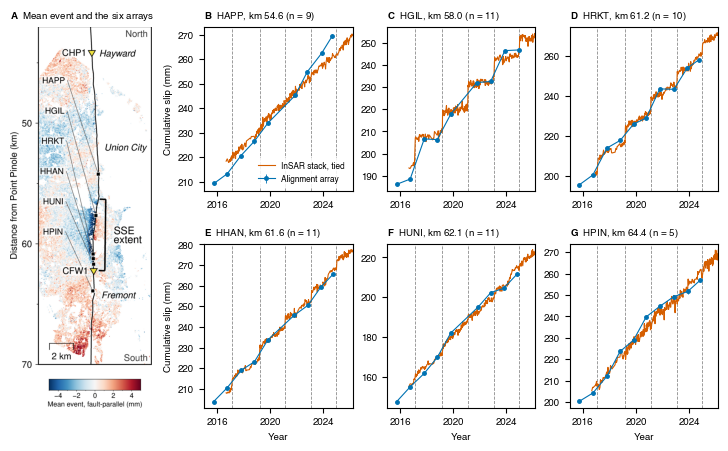

In [6]:
# A) the map: the rotated fault map of Fig 1A over the mean-event fault-parallel field of 06, resampled to a
# regular lon/lat grid (nearest pixel)
event_fields = np.load(event_field_file)
fp_event = np.asarray(event_fields["fp_event"], float)                 # mm, on 06's UTM box grid (pixel centres X, Y)
event_x = np.asarray(event_fields["X"], float)
event_y = np.asarray(event_fields["Y"], float)
x_step = float(event_x[0, 1] - event_x[0, 0])
y_step = float(event_y[1, 0] - event_y[0, 0])
assert np.allclose(np.diff(event_x, axis=1), x_step) and np.allclose(np.diff(event_y, axis=0), y_step), "06's grid is not regular"
frame = utils.strike_frame(int(event_fields["epsg"]), strike_map, trace.ft_lon.values, trace.ft_lat.values)
_, _, corners = utils.fault_map_corners(frame, map_u_km, map_half_km)
lon_axis, lat_axis, event_lonlat = utils.utm_grid_to_lonlat(fp_event, float(event_x[0, 0]), x_step, float(event_y[0, 0]), y_step,
                                                            frame["to_utm"], corners)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
# display reference: the mid-point of the median event slip west and east of the trace (section 5). The side of the
# fault is the sign of the cross product of the local trace direction (pointing south) with the vector from the
# nearest trace vertex to the node; positive is east
trace_x = trace.ft_lon.values * km_per_deg_lon
trace_y = trace.ft_lat.values * km_per_deg_lat
node_x = lon_grid.ravel() * km_per_deg_lon
node_y = lat_grid.ravel() * km_per_deg_lat
nearest = cKDTree(np.c_[trace_x, trace_y]).query(np.c_[node_x, node_y])[1]
ahead = np.clip(nearest + 1, 0, len(trace_x) - 1)
behind = np.clip(nearest - 1, 0, len(trace_x) - 1)
dir_x = trace_x[ahead] - trace_x[behind]
dir_y = trace_y[ahead] - trace_y[behind]
if trace.ft_lat.values[0] < trace.ft_lat.values[-1]:          # the file runs south to north: turn the direction to point south
    dir_x = -dir_x
    dir_y = -dir_y
east_of_trace = (dir_x * (node_y - trace_y[nearest]) - dir_y * (node_x - trace_x[nearest]) > 0).reshape(lon_grid.shape)
assert 0.2 < east_of_trace.mean() < 0.8, f"east/west split looks wrong: {east_of_trace.mean():.2f} of the map east of the trace"
has_event = np.isfinite(event_lonlat)
assert (has_event & east_of_trace).sum() > 1000 and (has_event & ~east_of_trace).sum() > 1000, "the event field is missing one side of the fault"
event_west = np.nanmedian(event_lonlat[~east_of_trace])
event_east = np.nanmedian(event_lonlat[east_of_trace])
event_lonlat = event_lonlat - 0.5 * (event_west + event_east)
print(f"mean event display reference: west {event_west:+.2f}, east {event_east:+.2f} mm; mid-point removed")
grid_ll = xr.DataArray(event_lonlat, coords={"lat": lat_axis, "lon": lon_axis}, dims=("lat", "lon"))
cpt_event = utils.write_cpt(os.path.join(out_dir, "event_RdBu_r.cpt"), "RdBu_r", -event_lim, event_lim)
# the six arrays as black squares; their codes in a column on the west side, spread along strike and tied to each
# square by a thin leader (HRKT, HHAN and HUNI lie within 1 km of each other, 0.1 cm on this map), clear of the
# CFW1 label
array_u, array_v = utils.to_uv(frame, array_pos.lon.values, array_pos.lat.values)
assert np.all(np.diff(array_u) > 0), "array_codes must run north to south"
array_symbols = []
array_labels = []
for code, u_array, v_array, u_label in zip(array_pos.index, array_u, array_v, array_label_u_km):
    leader_lon, leader_lat = utils.uv_to_lonlat(frame, [u_array, u_label], [v_array, -2.4])
    array_symbols.append(dict(x=leader_lon, y=leader_lat, pen="0.3p,gray30"))
    label_lon, label_lat = utils.uv_to_lonlat(frame, [u_label], [-2.6])
    array_labels.append(dict(x=label_lon[0], y=label_lat[0], text=code, justify="RM", font="6.5p,Helvetica"))
array_symbols.append(dict(x=array_pos.lon.values, y=array_pos.lat.values, style="s0.14c", fill="black", pen="0.3p,white"))
section = pd.read_csv(lengths_file).set_index("name").loc["tulepond_creep_length"]     # the SSE extent bracket, as Fig 1A

map_png = os.path.join(out_dir, "qc_arrays_map_panel.png")
gmt_map = pygmt.Figure()
with pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
                  MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p"):   # as Fig 1
    utils.fault_map_panel(gmt_map, frame, grid_ll, cpt_event, map_h_cm, trace.ft_lon.values, trace.ft_lat.values, creepmeters,
                          (section.km_lo, section.km_hi), letter=None, colorbar_frame="xa2f1+lMean event, fault-parallel (mm)",
                          extra_symbols=array_symbols, extra_labels=array_labels, u_range_km=map_u_km, half_km=map_half_km, scale_km=2)
gmt_map.savefig(map_png, dpi=600, crop="+gwhite")

# B to G) the arrays since 2015 with the InSAR, two rows of three, beside the map
utils.mpl_paper_style(base=7)
fig = plt.figure(figsize=(7.2, 4.4), constrained_layout=True)          # 18.3 cm wide
grid_spec = fig.add_gridspec(2, 4, width_ratios=[1.0, 1, 1, 1])             # the map column: the tall rotated map
ax_map = fig.add_subplot(grid_spec[:, 0])
ax_map.imshow(plt.imread(map_png))
ax_map.axis("off")
utils.panel_title(ax_map, "A", "Mean event and the six arrays")
for i, (code, array) in enumerate(arrays.items()):
    insar_dates, insar_slip, n_crossings = stacks[code]
    ax = fig.add_subplot(grid_spec[i // 3, 1 + i % 3])
    recent = array.year >= zoom_t0
    ax.errorbar(array.year[recent], array.cum_mm[recent], yerr=array.std_mm[recent], fmt="o", ms=2.5, color=aa_color, ecolor=aa_color,
                elinewidth=0.6, lw=0.8, ls="-", label="Alignment array")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color, label="InSAR stack, tied")
    for step_epoch in insar_events.onset_lo:
        ax.axvline(step_epoch, color="0.55", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(zoom_t0, 2026.2)
    ax.set_xticks([2016, 2020, 2024])
    y_lo = min(np.nanmin(insar_slip), array.cum_mm[recent].min())
    y_hi = max(np.nanmax(insar_slip), array.cum_mm[recent].max())
    ax.set_ylim(y_lo - 3, y_hi + 3)
    if i % 3 == 0:
        ax.set_ylabel("Cumulative slip (mm)")
    if i >= 3:
        ax.set_xlabel("Year")
    if i == 0:
        ax.legend(fontsize=6, loc="lower right")
    utils.panel_title(ax, "BCDEFG"[i], f"{code}, km {array_pos.km[code]:.1f} (n = {n_crossings})", size=7)
f_arrays = os.path.join(fig_dir, f"figS_tulepond_arrays_insar_{params}_stack{stack_km:g}km.png")
fig.savefig(f_arrays, dpi=600)
fig.savefig(f_arrays.replace(".png", ".pdf"))
print("Saved figure to:", f_arrays)
plt.show()

## 6. The HRKT event history (bimonthly era only)

HRKT was surveyed about every two months until mid-2007 and annually after that. The detector and the joint model
run on the bimonthly era only, because the annual cycle of the model cannot be resolved from annual surveys and a
one-year window cannot place an event in its season. The era ends at the last survey that closes an interval of
`dense_window_days` (130 d) or less.

**Detection statistic.** For each survey interval $i$,

$$e_i = (U_i - U_{i-1}) - v\,(t_i - t_{i-1}),$$

where $U_i$ is the cumulative slip at survey $i$ (mm), $t_i$ its time (decimal years) and $v$ the inter-event rate
(mm/yr). An interval is flagged when $e_i > \theta$, with $\theta$ = `thr_mm` = 6 mm, a fixed threshold chosen by eye
against visually distinct steps (section 9 shows the effect of this choice). Consecutive flagged intervals are
merged into one event, whose window runs from the first to the last survey of the merged intervals.

**Joint model.** The flagged events are fitted with the joint model of section 3, with the step of event $k$ at
$\tau_k$, the last survey before it (as `onset_lo` in 04). Any time inside the window gives the same fit, because no
survey falls inside it. The formal 1-sigma error of each step is

$$\sigma_{s_k} = \sqrt{\hat\sigma^2 \left[(G^\top G)^{-1}\right]_{kk}}, \qquad
\hat\sigma^2 = \frac{1}{N - P} \sum_{i=1}^{N} r_i^2,$$

where $G$ is the design matrix, $N$ the number of surveys, $P$ the number of model parameters (4 + $K$) and $r_i$
the residual at survey $i$ (mm).

**The 2-sigma rule.** While the smallest ratio $s_k / \sigma_{s_k}$ is under `min_step_sigma` (2), the event with
that ratio is dropped and the model refitted.

**Two passes.** In pass 1 the rate $v$ is the slope of a least-squares line through all surveys of the era. In pass
2 the detection is repeated with the inter-event rate $v$ fitted by the joint model of pass 1.

**The threshold in units of sigma.** The noise of the detection statistic is measured by the robust standard
deviation [citation needed]

$$\sigma_R = 1.4826 \, \mathrm{median}_i \left| e_i - \mathrm{median}(e) \right|,$$

computed on the statistic of the last pass; $\theta / \sigma_R$ is printed and registered. The annual amplitude is
$A = \sqrt{a^2 + b^2}$ and the RMS is the root mean square of the residuals.

The catalogue keeps the survey window [`onset_lo`, `onset_hi`] of each event; `onset_mid`, the window midpoint, is
used only for labels, plot positions and sorting. The onset is equally likely anywhere in its window, so every
statistic of the onset times (notebook 13, section 6) draws it uniformly within the window.

The quiet interval is the longest gap between the end of one event window and the start of the next. It must span
the 1989 Loma Prieta earthquake (asserted).

In [7]:
def bimonthly_era(array):
    """Bimonthly era of an array record (section 6).

    Parameters
    ----------
    array : pandas.DataFrame
        The array record (year, cum_mm, std_mm), sorted by year.

    Returns
    -------
    pandas.DataFrame
        The record up to the last survey that closes an interval of dense_window_days or less.
    """
    gap_days = np.diff(array.year.values) * 365.25
    last = int(np.max(np.where(gap_days <= dense_window_days)[0])) + 1
    return array.iloc[:last + 1].reset_index(drop=True)


def interval_excess(survey_yr, cum_slip, rate_mm_yr):
    """Detection statistic e_i of every survey interval (section 6).

    Parameters
    ----------
    survey_yr : numpy.ndarray
        Survey times (decimal years).
    cum_slip : numpy.ndarray
        Cumulative slip at each survey (mm).
    rate_mm_yr : float
        Inter-event rate (mm/yr).

    Returns
    -------
    numpy.ndarray
        Step of each interval minus the rate times its length (mm).
    """
    return np.diff(cum_slip) - rate_mm_yr * np.diff(survey_yr)


def detect_intervals(survey_yr, cum_slip, rate_mm_yr, threshold_mm):
    """Flag the survey intervals whose detection statistic exceeds the threshold.

    Consecutive flagged intervals are merged into one event.

    Parameters
    ----------
    survey_yr, cum_slip : numpy.ndarray
        Survey times (decimal years) and cumulative slip (mm).
    rate_mm_yr : float
        Inter-event rate (mm/yr).
    threshold_mm : float
        Detection threshold (mm).

    Returns
    -------
    events : list of [int, int]
        Survey index of the start and end of each event window.
    excess : numpy.ndarray
        Detection statistic of every interval (mm).
    """
    excess = interval_excess(survey_yr, cum_slip, rate_mm_yr)
    events = []
    for i in np.where(excess > threshold_mm)[0]:
        if events and i == events[-1][1]:            # continues the previous flagged interval
            events[-1][1] = i + 1
        else:
            events.append([i, i + 1])
    return events, excess


def fit_steps(survey_yr, cum_slip, events):
    """Least-squares fit of the joint model with one step per event (section 6).

    The step of each event is at the last survey before it, as the step at onset_lo in 04.

    Parameters
    ----------
    survey_yr, cum_slip : numpy.ndarray
        Survey times (decimal years) and cumulative slip (mm).
    events : list of [int, int]
        Survey index of the start and end of each event window.

    Returns
    -------
    coef : numpy.ndarray
        Constant, rate, annual sine and cosine, then the steps (mm, mm/yr).
    design_G : numpy.ndarray
        Design matrix.
    step_err : numpy.ndarray
        Formal 1-sigma error of each step (mm).
    """
    step_epochs = []
    for i_start, i_end in events:
        step_epochs.append(survey_yr[i_start])
    design_G = design_matrix(survey_yr, step_epochs)
    coef, *_ = np.linalg.lstsq(design_G, cum_slip, rcond=None)
    residual = cum_slip - np.dot(design_G, coef)
    variance = float(np.sum(residual ** 2) / (len(survey_yr) - design_G.shape[1]))
    step_err = np.sqrt(variance * np.diag(np.linalg.inv(np.dot(design_G.T, design_G))))[n_background:]
    return coef, design_G, step_err


def run_detector(survey_yr, cum_slip, threshold_mm):
    """Detector of section 6: two passes of detection and joint fit, with the 2-sigma rule.

    Parameters
    ----------
    survey_yr, cum_slip : numpy.ndarray
        Survey times (decimal years) and cumulative slip (mm).
    threshold_mm : float
        Detection threshold (mm).

    Returns
    -------
    catalogue : pandas.DataFrame
        One row per event: onset_lo, onset_hi, onset_mid, window_days, amplitude_mm, amp_err.
    excess : numpy.ndarray
        Detection statistic of the last pass (mm).
    inter_event_rate : float
        Inter-event rate fitted in the last pass (mm/yr).
    coef, design_G : numpy.ndarray
        Coefficients and design matrix of the last fit.
    n_dropped : int
        Detections dropped by the 2-sigma rule in the last pass.
    """
    inter_event_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])          # pass 1: the slope of a straight line
    for _ in range(n_pass):
        events, excess = detect_intervals(survey_yr, cum_slip, inter_event_rate, threshold_mm)
        n_dropped = 0
        while True:
            coef, design_G, step_err = fit_steps(survey_yr, cum_slip, events)
            if len(events) == 0:
                break
            ratio = coef[n_background:] / step_err
            if ratio.min() >= min_step_sigma:
                break
            i_start, i_end = events.pop(int(np.argmin(ratio)))               # drop the weakest event
            n_dropped += 1
            print(f"      dropped {survey_yr[i_start]:.2f}-{survey_yr[i_end]:.2f}: fitted step {ratio.min():.1f} sigma (< {min_step_sigma:g})")
        inter_event_rate = float(coef[1])                                     # pass 2 uses the fitted rate
    catalogue_rows = []
    for (i_start, i_end), amplitude, err in zip(events, coef[n_background:], step_err):
        catalogue_rows.append(dict(onset_lo=survey_yr[i_start], onset_hi=survey_yr[i_end],
                                   onset_mid=0.5 * (survey_yr[i_start] + survey_yr[i_end]),   # labels, plot positions, sort keys only
                                   window_days=(survey_yr[i_end] - survey_yr[i_start]) * 365.25,
                                   amplitude_mm=float(amplitude), amp_err=float(err)))
    catalogue = pd.DataFrame(catalogue_rows, columns=["onset_lo", "onset_hi", "onset_mid", "window_days", "amplitude_mm", "amp_err"])   # columns kept when empty
    return catalogue, excess, inter_event_rate, coef, design_G, n_dropped


hrkt = bimonthly_era(arrays[site])
survey_yr = hrkt.year.values
cum_slip = hrkt.cum_mm.values
dense_era_end = float(survey_yr[-1])
hrkt_events, excess, inter_event_rate, coef, design_G, n_dropped = run_detector(survey_yr, cum_slip, thr_mm)
excess_sigma = utils.robust_sigma(excess)
annual_mm = float(np.hypot(coef[2], coef[3]))
rms_mm = float(np.sqrt(np.mean((cum_slip - np.dot(design_G, coef)) ** 2)))
assert len(hrkt_events) > 0, f"no {site} events at {thr_mm:g} mm"
assert hrkt_events.window_days.max() <= dense_window_days, "an event window longer than the bimonthly cadence"
# the event catalogue for 12 (event table, seasonality) and 13 (repeat intervals, forecast)
hrkt_events.round(4).to_csv(os.path.join(out_dir, f"{site.lower()}_aa_events.csv"), index=False)

print(f"{site} bimonthly era: {len(survey_yr)} surveys {survey_yr.min():.2f}-{dense_era_end:.2f}, "
      f"median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d (annual surveys after {dense_era_end:.2f} are not used)")
print(f"threshold {thr_mm:g} mm = {thr_mm / excess_sigma:.1f} robust sigma (sigma {excess_sigma:.2f} mm); "
      f"joint model: inter-event rate {inter_event_rate:.2f} mm/yr, annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm; "
      f"{n_dropped} detection(s) dropped under {min_step_sigma:g} sigma")
print(f"{len(hrkt_events)} events, steps {hrkt_events.amplitude_mm.min():.1f} to {hrkt_events.amplitude_mm.max():.1f} mm "
      f"(median {hrkt_events.amplitude_mm.median():.1f})")
# the event table: the survey window (window_lo, last survey before the step; window_hi, first survey after it) and
# the joint-model step with its formal 1-sigma error
event_table = hrkt_events[["onset_lo", "onset_hi", "window_days", "amplitude_mm", "amp_err"]].rename(
    columns={"onset_lo": "window_lo (yr)", "onset_hi": "window_hi (yr)", "window_days": "window (d)",
             "amplitude_mm": "step (mm)", "amp_err": "1-sigma (mm)"})
print(event_table.round({"window_lo (yr)": 2, "window_hi (yr)": 2, "window (d)": 0, "step (mm)": 1, "1-sigma (mm)": 1}).to_string(index=False))

# the quiet interval: the longest gap between event windows, the surveys inside it and their largest step
gaps_yr = hrkt_events.onset_lo.values[1:] - hrkt_events.onset_hi.values[:-1]
i_gap = int(np.argmax(gaps_yr))
quiet_start = float(hrkt_events.onset_hi.values[i_gap])
quiet_end = float(hrkt_events.onset_lo.values[i_gap + 1])
in_quiet = (survey_yr >= quiet_start) & (survey_yr <= quiet_end)
n_quiet = int(((survey_yr > quiet_start) & (survey_yr < quiet_end)).sum())
max_step_quiet = float(np.max(np.diff(cum_slip[in_quiet])))
print(f"quiet interval {quiet_start:.2f} to {quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr): {n_quiet} surveys, "
      f"largest step {max_step_quiet:.1f} mm; Loma Prieta {loma_prieta}")
assert quiet_start < loma_prieta < quiet_end, "the longest quiet interval does not span Loma Prieta: check the catalogue"

HRKT bimonthly era: 159 surveys 1979.72-2007.44, median spacing 63 d (annual surveys after 2007.44 are not used)
threshold 6 mm = 2.5 robust sigma (sigma 2.43 mm); joint model: inter-event rate 2.95 mm/yr, annual 1.90 mm, rms 2.11 mm; 0 detection(s) dropped under 2 sigma
9 events, steps 2.2 to 12.3 mm (median 8.2)
 window_lo (yr)  window_hi (yr)  window (d)  step (mm)  1-sigma (mm)
        1983.04         1983.38       124.0        9.2           0.9
        1985.95         1986.18        85.0        6.5           0.9
        1988.29         1988.41        43.0        2.2           1.0
        1993.18         1993.35        63.0        6.8           1.0
        1997.32         1997.47        56.0       10.0           0.9
        2000.06         2000.23        63.0       12.3           0.9
        2002.86         2003.03        63.0        8.2           1.0
        2004.99         2005.17        69.0        9.0           1.3
        2005.86         2006.06        70.0        4.6         

## 7. Along strike: the neighbouring bimonthly arrays inside the HRKT event windows

Three other arrays were surveyed about every two months: HAPP (km 54.6, 1.6 km north of the section) and HCAM and
HPMD (km 65.3 and 65.7, about 3 km south of it). Each is run through the detector of section 6 over its own
bimonthly era at the same threshold. For every HRKT event window that falls inside that era, the excess step of the
neighbour is

$$E = \left[U'(t_\mathrm{hi}) - U'(t_\mathrm{lo})\right] - v'\,(t_\mathrm{hi} - t_\mathrm{lo}),$$

where $t_\mathrm{lo}$ and $t_\mathrm{hi}$ are the ends of the HRKT window (decimal years), $U'$ the cumulative slip of
the neighbour interpolated linearly to those times (mm) and $v'$ its own inter-event rate (mm/yr). $E$ is also given
in units of the neighbour's own robust sigma, $E / \sigma_R'$.

In [8]:
neighbour_rows = []
neighbour_runs = {}
for code in neighbour_codes:
    array = bimonthly_era(utils.load_aa(common_paths["aa_dir"], code))
    years = array.year.values
    cum = array.cum_mm.values
    own_events, own_excess, own_rate, _, _, _ = run_detector(years, cum, thr_mm)
    own_sigma = utils.robust_sigma(own_excess)
    neighbour_runs[code] = (array, own_events, own_excess, own_sigma)
    own_event_text = []
    for own_event in own_events.itertuples():
        own_event_text.append(f"{own_event.onset_lo:.2f}-{own_event.onset_hi:.2f} ({own_event.amplitude_mm:.1f} mm)")
    print(f"{code}: bimonthly era {years.min():.2f}-{years.max():.2f}, {len(years)} surveys, sigma {own_sigma:.2f} mm "
          f"({thr_mm:g} mm = {thr_mm / own_sigma:.1f} sigma), {len(own_events)} own events: " + ", ".join(own_event_text))
    for event in hrkt_events.itertuples():
        if event.onset_lo < years.min() or event.onset_hi > years.max():
            continue                                                       # this HRKT window is outside the array's bimonthly era
        step = np.interp(event.onset_hi, years, cum) - np.interp(event.onset_lo, years, cum)
        excess_here = step - own_rate * (event.onset_hi - event.onset_lo)
        neighbour_rows.append(dict(array=code, hrkt_window_lo=event.onset_lo, hrkt_window_hi=event.onset_hi, hrkt_step_mm=event.amplitude_mm,
                                   excess_mm=excess_here, excess_sigma=excess_here / own_sigma))
        print(f"  HRKT {event.onset_lo:.2f}-{event.onset_hi:.2f} ({event.amplitude_mm:4.1f} mm): {code} excess {excess_here:+5.1f} mm "
              f"({excess_here / own_sigma:+.1f} sigma)")
neighbours = pd.DataFrame(neighbour_rows)
neighbours.round(3).to_csv(os.path.join(out_dir, "aa_alongstrike_neighbours.csv"), index=False)
print(f"largest excess at a neighbour inside an HRKT window: {neighbours.excess_sigma.max():+.1f} sigma "
      f"({len(neighbours)} array-windows)")

  AA HAPP: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1995.007 vs 1/28/1995, 1996.820 vs 10/22/1996, 2024.680 vs 10/5/2024; 0 without a readable date
HAPP: bimonthly era 1979.73-2007.84, 157 surveys, sigma 1.93 mm (6 mm = 3.1 sigma), 0 own events: 
  HRKT 1983.04-1983.38 ( 9.2 mm): HAPP excess  -3.8 mm (-2.0 sigma)
  HRKT 1985.95-1986.18 ( 6.5 mm): HAPP excess  +0.7 mm (+0.3 sigma)
  HRKT 1988.29-1988.41 ( 2.2 mm): HAPP excess  +0.5 mm (+0.3 sigma)
  HRKT 1993.18-1993.35 ( 6.8 mm): HAPP excess  -2.0 mm (-1.0 sigma)
  HRKT 1997.32-1997.47 (10.0 mm): HAPP excess  +1.6 mm (+0.9 sigma)
  HRKT 2000.06-2000.23 (12.3 mm): HAPP excess  -0.7 mm (-0.4 sigma)
  HRKT 2002.86-2003.03 ( 8.2 mm): HAPP excess  +0.7 mm (+0.3 sigma)
  HRKT 2004.99-2005.17 ( 9.0 mm): HAPP excess  -0.3 mm (-0.2 sigma)
  HRKT 2005.86-2006.06 ( 4.6 mm): HAPP excess  -0.8 mm (-0.4 sigma)
HCAM: bimonthly era 1990.11-2007.84, 105 surveys, sigma 1.28 mm (6 mm

## 8. QC figures: the 45-year record at the two longest bimonthly arrays

HRKT (km 61.2, inside the section) and HAPP (km 54.6, north of it), one figure each. Panel A shows the whole record
with the array's own detections shaded over the bimonthly era, and an inset since 2015 with the InSAR stack. Panel B
shows the detection statistic $e_i$ over the bimonthly era as a step over each survey interval. The HRKT windows are
outlined on the HAPP panels. These are QC figures, not the paper's Fig 3.

Saved the HRKT QC history figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/qc_aa_history_HRKT_thr6mm_nev9.png


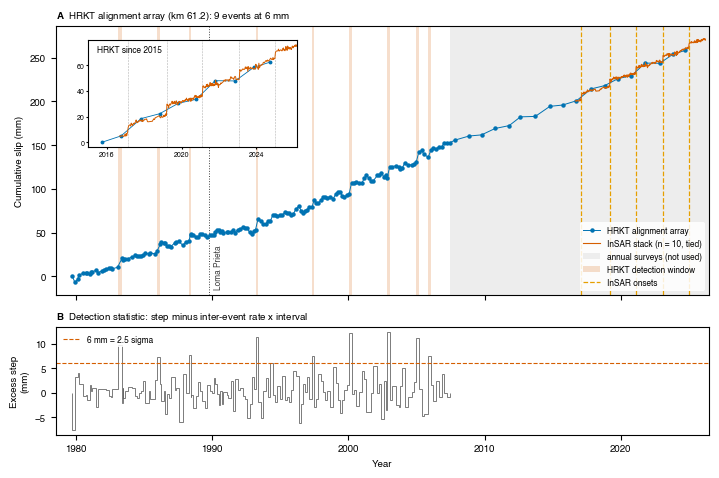

Saved the HAPP QC history figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/qc_aa_history_HAPP_thr6mm_nev0.png


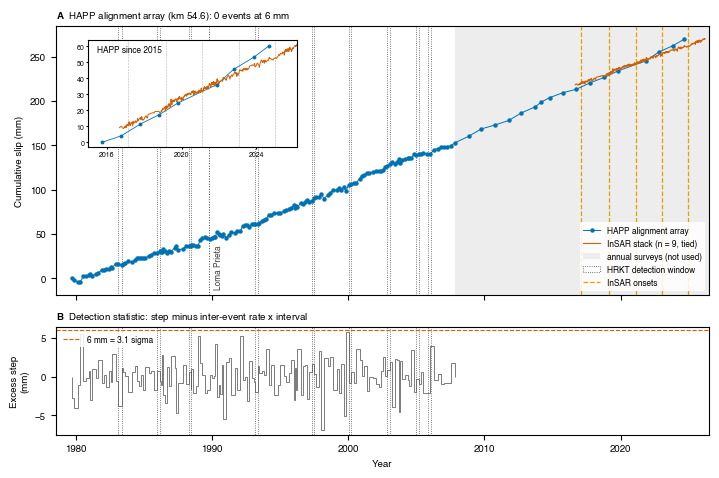

In [9]:
def draw_history(code, catalogue, excess_code, sigma_code, era_end, reference_windows=None):
    """Draw the QC figure of one array (section 8).

    Parameters
    ----------
    code : str
        Array code.
    catalogue : pandas.DataFrame
        The array's own detections.
    excess_code : numpy.ndarray
        Detection statistic over the bimonthly era (mm).
    sigma_code : float
        Robust sigma of the detection statistic (mm).
    era_end : float
        End of the bimonthly era (decimal year).
    reference_windows : pandas.DataFrame, optional
        Event windows of another array to outline (the HRKT windows on the HAPP figure).
    """
    array = arrays[code]
    era = array[array.year <= era_end + 1e-9]
    insar_dates, insar_slip, n_crossings = stacks[code]
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.8), sharex=True, height_ratios=[1.5, 0.6])
    # A) the record, its detections shaded, the InSAR step epochs (onset_lo) dashed
    ax = axes[0]
    ax.plot(array.year, array.cum_mm, "o", ms=2.2, color=aa_color, lw=0.7, ls="-", zorder=3, label=f"{code} alignment array")
    ax.plot(insar_dates, insar_slip, "-", lw=0.8, color=insar_color, zorder=5, label=f"InSAR stack (n = {n_crossings}, tied)")
    ax.axvspan(era_end, 2026.5, color="0.93", lw=0, zorder=0, label="annual surveys (not used)")
    for event in catalogue.itertuples():
        ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.20, lw=0, zorder=1,
                   label=f"{code} detection window" if event.Index == 0 else None)
    if reference_windows is not None:
        for j, event in enumerate(reference_windows.itertuples()):
            ax.axvspan(event.onset_lo, event.onset_hi, facecolor="none", edgecolor="0.3", lw=0.6, ls=":", zorder=2,
                       label="HRKT detection window" if j == 0 else None)
    for i, step_epoch in enumerate(insar_events.onset_lo):
        ax.axvline(step_epoch, color=det_color, lw=0.9, ls="--", zorder=2, label="InSAR onsets" if i == 0 else None)
    ax.axvline(loma_prieta, color="0.25", lw=0.7, ls=":", zorder=2)
    ax.text(loma_prieta + 0.35, 0.02, "Loma Prieta", transform=ax.get_xaxis_transform(), rotation=90, fontsize=6, color="0.25", va="bottom")
    ax.set_ylabel("Cumulative slip (mm)")
    ax.legend(fontsize=6, loc="lower right")
    utils.panel_title(ax, "A", f"{code} alignment array (km {array_pos.km[code]:.1f}): {len(catalogue)} events at {thr_mm:g} mm")
    # the inset: this array since 2015 against its InSAR stack, zeroed at the first survey
    recent = array[array.year >= zoom_t0]
    zero = float(recent.cum_mm.iloc[0])
    inset = ax.inset_axes([0.05, 0.55, 0.32, 0.40])
    inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.8, color=aa_color, lw=0.6, ls="-")
    inset.plot(insar_dates, insar_slip - zero, "-", lw=0.7, color=insar_color)
    for step_epoch in insar_events.onset_lo:
        inset.axvline(step_epoch, color="0.7", lw=0.4, ls="--", zorder=0)
    inset.set_xlim(zoom_t0, 2026.2)
    inset.set_xticks([2016, 2020, 2024])
    inset.tick_params(labelsize=5, length=1.5, pad=1.5)
    inset.text(0.04, 0.95, f"{code} since {zoom_t0:.0f}", transform=inset.transAxes, fontsize=6, va="top")
    # B) the detection statistic over the bimonthly era: one value per survey interval
    ax = axes[1]
    ax.stairs(excess_code, era.year.values, color="0.4", lw=0.6)
    ax.axhline(thr_mm, color=insar_color, lw=0.8, ls="--", label=f"{thr_mm:g} mm = {thr_mm / sigma_code:.1f} sigma")
    if reference_windows is not None:
        for event in reference_windows.itertuples():
            ax.axvspan(event.onset_lo, event.onset_hi, facecolor="none", edgecolor="0.3", lw=0.6, ls=":")
    ax.set_ylabel("Excess step\n(mm)")
    ax.legend(fontsize=6, loc="upper left")
    utils.panel_title(ax, "B", "Detection statistic: step minus inter-event rate x interval")
    axes[-1].set_xlabel("Year")
    axes[-1].set_xlim(1978.5, 2026.5)
    fig.tight_layout()
    f_history = os.path.join(fig_dir, f"qc_aa_history_{code}_thr{thr_mm:g}mm_nev{len(catalogue)}.png")
    fig.savefig(f_history, dpi=300)
    print(f"Saved the {code} QC history figure to: {f_history}")
    plt.show()


happ_era, happ_events, happ_excess, happ_sigma = neighbour_runs["HAPP"]
draw_history("HRKT", hrkt_events, excess, excess_sigma, dense_era_end)
draw_history("HAPP", happ_events, happ_excess, happ_sigma, float(happ_era.year.max()), reference_windows=hrkt_events)

## 9. Threshold sweep (supplement)

The detector of section 6 (bimonthly era, 2-sigma rule) is run with three thresholds: $\theta = 3\sigma_g$, 6 mm and
5 mm. Here $\sigma_g$ is the robust sigma of the detection statistic $e_i$ computed with the global rate, the slope of
a least-squares line through all surveys of the era. The left panels show the detection statistic (one value per
survey interval) with each threshold and the detected windows. The right panels show the fitted step of each
detected event with its 1-sigma error; the horizontal bar spans its window.

threshold 3 sigma = 7.5 mm:
      dropped 1988.29-1988.41: fitted step -1.2 sigma (< 2)
threshold 6 mm:
threshold 5 mm:
      dropped 2003.97-2004.14: fitted step 1.1 sigma (< 2)
       threshold  thr_mm  n_events  n_dropped  rate
3 sigma = 7.5 mm    7.53         5          1  4.24
            6 mm    6.00         9          0  2.95
            5 mm    5.00        12          1  2.44


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_hrkt_threshold_sweep_3sig-6mm-5mm.png


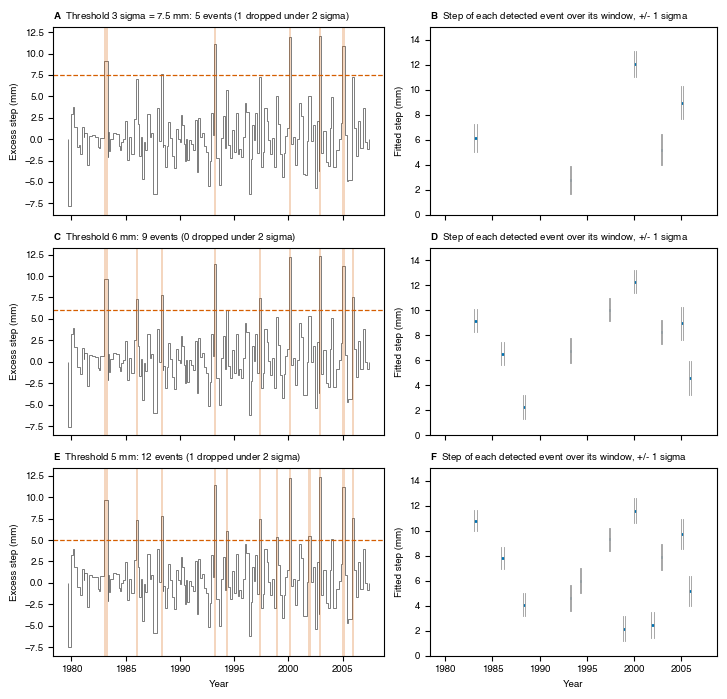

In [10]:
# the robust sigma of the detection statistic at the global rate sets the 3-sigma threshold
global_rate = float(np.polyfit(survey_yr, cum_slip, 1)[0])
excess_global = interval_excess(survey_yr, cum_slip, global_rate)
sigma_global = utils.robust_sigma(excess_global)
cases = [(f"3 sigma = {3 * sigma_global:.1f} mm", 3 * sigma_global), ("6 mm", 6.0), ("5 mm", 5.0)]

fig, axes = plt.subplots(len(cases), 2, figsize=(7.2, 7.0), width_ratios=[1.15, 1.0], sharex=True)
sweep_rows = []
for i_case, (label, threshold_mm) in enumerate(cases):
    print(f"threshold {label}:")
    sweep_events, sweep_excess, sweep_rate, sweep_coef, sweep_G, sweep_dropped = run_detector(survey_yr, cum_slip, threshold_mm)
    sweep_rows.append(dict(threshold=label, thr_mm=threshold_mm, n_events=len(sweep_events), n_dropped=sweep_dropped, rate=sweep_rate))
    # left: the detection statistic with this threshold
    ax = axes[i_case, 0]
    ax.stairs(sweep_excess, survey_yr, color="0.4", lw=0.6)
    ax.axhline(threshold_mm, color=insar_color, lw=0.9, ls="--")
    for event in sweep_events.itertuples():
        ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.25, lw=0)
    ax.set_ylabel("Excess step (mm)")
    utils.panel_title(ax, "ACE"[i_case], f"Threshold {label}: {len(sweep_events)} events ({sweep_dropped} dropped under {min_step_sigma:g} sigma)")
    # right: the fitted steps, the horizontal bar bounding each event's survey window
    ax = axes[i_case, 1]
    ax.hlines(sweep_events.amplitude_mm, sweep_events.onset_lo, sweep_events.onset_hi, color=aa_color, lw=2.0)
    for event in sweep_events.itertuples():
        ax.plot([event.onset_lo, event.onset_lo], [event.amplitude_mm - event.amp_err, event.amplitude_mm + event.amp_err], "-", color="0.6", lw=0.6)
        ax.plot([event.onset_hi, event.onset_hi], [event.amplitude_mm - event.amp_err, event.amplitude_mm + event.amp_err], "-", color="0.6", lw=0.6)
    ax.set_ylim(0, 15)
    ax.set_ylabel("Fitted step (mm)")
    utils.panel_title(ax, "BDF"[i_case], "Step of each detected event over its window, +/- 1 sigma")
    if i_case == len(cases) - 1:
        axes[i_case, 0].set_xlabel("Year")
        ax.set_xlabel("Year")
fig.tight_layout()
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(os.path.join(out_dir, "hrkt_threshold_sweep.csv"), index=False)
print(sweep.round(2).to_string(index=False))
f_sweep = os.path.join(fig_dir, "figS_hrkt_threshold_sweep_3sig-6mm-5mm.png")
fig.savefig(f_sweep, dpi=300)
fig.savefig(f_sweep.replace(".png", ".pdf"))
print("Saved figure to:", f_sweep)
plt.show()

## 10. Registry: the stats sidecar `11_aa_stats.txt` and the registered numbers

In [11]:
stats_lines += [f"{site} EVENT HISTORY (bimonthly era {survey_yr.min():.2f}-{dense_era_end:.2f}): {len(survey_yr)} surveys, "
                f"median spacing {np.median(np.diff(survey_yr)) * 365.25:.0f} d",
                f"detection: fixed {thr_mm:g} mm excess per interval (= {thr_mm / excess_sigma:.1f} robust sigma, sigma {excess_sigma:.2f} mm); "
                f"steps under {min_step_sigma:g} sigma dropped ({n_dropped}); joint model rate {inter_event_rate:.2f} mm/yr, "
                f"annual {annual_mm:.2f} mm, rms {rms_mm:.2f} mm",
                f"{len(hrkt_events)} events, steps {hrkt_events.amplitude_mm.min():.1f}-{hrkt_events.amplitude_mm.max():.1f} mm "
                f"(median {hrkt_events.amplitude_mm.median():.1f})"]
for event in hrkt_events.itertuples():
    stats_lines.append(f"  window {event.onset_lo:.2f}-{event.onset_hi:.2f} ({event.window_days:3.0f} d)  step {event.amplitude_mm:5.1f} +/- {event.amp_err:.1f} mm")
stats_lines += [f"quiet interval {quiet_start:.2f}-{quiet_end:.2f} ({quiet_end - quiet_start:.1f} yr), {n_quiet} surveys, "
                f"largest step {max_step_quiet:.1f} mm, spans Loma Prieta {loma_prieta}",
                f"InSAR-era steps on the HRKT stack: mean {hrkt_insar_steps.mean():.1f}, median {np.median(hrkt_insar_steps):.1f} mm, "
                f"range {hrkt_insar_steps.min():.1f}-{hrkt_insar_steps.max():.1f} mm (per event: {', '.join(f'{v:.1f}' for v in hrkt_insar_steps)})",
                "", "along strike (neighbour excess inside HRKT windows):", neighbours.round(2).to_string(index=False),
                "", "threshold sweep:", sweep.round(2).to_string(index=False)]
sidecar = REG.sidecar("11_aa", stats_lines)

REG.register("11_hrkt_n_surveys", len(survey_yr), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_first_yr", survey_yr.min(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_dense_era_end_yr", dense_era_end, "decyear", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_median_spacing_d", np.median(np.diff(survey_yr)) * 365.25, "d", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_sigma_mm", excess_sigma, "mm", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_threshold_sigma", thr_mm / excess_sigma, "1", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_rate_mm_yr", inter_event_rate, "mm/yr", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_annual_mm", annual_mm, "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_n_events", len(hrkt_events), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_n_dropped_2sigma", n_dropped, "count", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_amp_min_mm", hrkt_events.amplitude_mm.min(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_amp_max_mm", hrkt_events.amplitude_mm.max(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_amp_median_mm", hrkt_events.amplitude_mm.median(), "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_amp_mean_mm", hrkt_events.amplitude_mm.mean(), "mm", 1, where="P9 event size", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_window_min_d", hrkt_events.window_days.min(), "d", 0, where="Fig3 caption", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_window_max_d", hrkt_events.window_days.max(), "d", 0, where="Fig3 caption", cell="detector", sidecar=sidecar)
REG.register("11_hrkt_insar_step_mean_mm", hrkt_insar_steps.mean(), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)
REG.register("11_hrkt_insar_step_median_mm", np.median(hrkt_insar_steps), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)
REG.register("11_hrkt_insar_step_min_mm", hrkt_insar_steps.min(), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)   # the range beside the mean
REG.register("11_hrkt_insar_step_max_mm", hrkt_insar_steps.max(), "mm", 1, where="P9 event size", cell="insar stack", sidecar=sidecar)
REG.register("11_quiet_start_yr", quiet_start, "decyear", 2, where="P9", cell="detector", sidecar=sidecar)
REG.register("11_quiet_end_yr", quiet_end, "decyear", 2, where="P9", cell="detector", sidecar=sidecar)
REG.register("11_quiet_max_step_mm", max_step_quiet, "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("11_neighbour_max_excess_sigma", neighbours.excess_sigma.max(), "sigma", 1, where="P9 along strike", cell="along strike", sidecar=sidecar)
REG.register("11_neighbour_n_windows", len(neighbours), "count", 0, where="P9 along strike", cell="along strike", sidecar=sidecar)
for code in ("HGIL", "HRKT"):
    for kind in ("event_median", "quiet_median"):
        rows = aa_steps[(aa_steps.code == code) & (aa_steps.kind == kind)]
        assert len(rows) == 1, f"{code}: no {kind} step since {zoom_t0:.0f}"
        REG.register(f"11_{code.lower()}_{kind}_mm", float(rows.step_mm.iloc[0]), "mm", 1, where="P9, Fig3", cell="arrays-insar", sidecar=sidecar)
for case in sweep.itertuples():
    REG.register(f"11_sweep_{case.thr_mm:.1f}mm_n_events", case.n_events, "count", 0, where="S threshold sweep", cell="sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/11_alignment_arrays/11_aa_stats.txt
  registered 11_hrkt_n_surveys = 159 count  -> P9, M8
  registered 11_hrkt_first_yr = 1979.7 decyear  -> M8
  registered 11_hrkt_dense_era_end_yr = 2007.44 decyear  -> M8
  registered 11_hrkt_median_spacing_d = 63 d  -> M8


  registered 11_hrkt_sigma_mm = 2.43 mm  -> M8
  registered 11_hrkt_threshold_sigma = 2.5 1  -> M8
  registered 11_hrkt_rate_mm_yr = 2.95 mm/yr  -> M8
  registered 11_hrkt_annual_mm = 1.9 mm  -> M8
  registered 11_hrkt_n_events = 9 count  -> P9, M8
  registered 11_hrkt_n_dropped_2sigma = 0 count  -> M8
  registered 11_hrkt_amp_min_mm = 2.2 mm  -> M8
  registered 11_hrkt_amp_max_mm = 12.3 mm  -> M8
  registered 11_hrkt_amp_median_mm = 8.2 mm  -> P9
  registered 11_hrkt_amp_mean_mm = 7.7 mm  -> P9 event size
  registered 11_hrkt_window_min_d = 43 d  -> Fig3 caption
  registered 11_hrkt_window_max_d = 124 d  -> Fig3 caption


  registered 11_hrkt_insar_step_mean_mm = 6.3 mm  -> P9 event size
  registered 11_hrkt_insar_step_median_mm = 6.5 mm  -> P9 event size
  registered 11_hrkt_insar_step_min_mm = 5.3 mm  -> P9 event size
  registered 11_hrkt_insar_step_max_mm = 6.8 mm  -> P9 event size
  registered 11_quiet_start_yr = 1988.41 decyear  -> P9


  registered 11_quiet_end_yr = 1993.18 decyear  -> P9
  registered 11_quiet_max_step_mm = 3.7 mm  -> P9
  registered 11_neighbour_max_excess_sigma = 1.5 sigma  -> P9 along strike
  registered 11_neighbour_n_windows = 21 count  -> P9 along strike
  registered 11_hgil_event_median_mm = 14.1 mm  -> P9, Fig3
  registered 11_hgil_quiet_median_mm = 0.4 mm  -> P9, Fig3
  registered 11_hrkt_event_median_mm = 12.0 mm  -> P9, Fig3
  registered 11_hrkt_quiet_median_mm = 3.8 mm  -> P9, Fig3
  registered 11_sweep_7.5mm_n_events = 5 count  -> S threshold sweep
  registered 11_sweep_6.0mm_n_events = 9 count  -> S threshold sweep
  registered 11_sweep_5.0mm_n_events = 12 count  -> S threshold sweep


Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md'